# Exercise 2: Agentic architectures for HydroMT / Wflow

You will run the same kind of hydrological question through agents of increasing complexity. For each one,
ask: *what did the extra structure buy me, and what did it cost?*

| # | Architecture | Pattern (Agentic Overview) |
|---|---|---|
| A0 | Plain LLM + fixed workflow | Deterministic workflow, no agent |
| A1 | Single agent (ReAct) | Dynamic orchestration: single agent |
| A2 | Generator-critic loop | Deterministic workflow: loop / generator-critic |
| A3 | Director + subagents + human-in-the-loop | Subagents (supervisor) + HITL + custom logic |
| A4 | Claude Agent SDK harness + skills | Agent harness + skills (code agent) |
| A5 | Router -> {LLM, ReAct, harness} -> human check | Composing harness agents inside a framework |

**Model:** wflow_sbm of the upper Moselle to Epinal (HydroMT build from `hydromt/`), forced with E-OBS for
2019-2020. Agents change parameters through **multipliers** (A0-A3, A5). The code agent (A4) can also write
Python that edits the NetCDF files directly.

Prerequisites:
- the course environment, with `verify_env.py` all OK;
- Julia `Wflow` 1.x;
- API keys in a `.env` file at the repo root or in a parent folder. Never paste keys into this notebook.

## Step 0: Setup
Pick the LLM provider for the LangGraph architectures: `"anthropic"` (Claude), `"mistral"` (Mistral on Azure
Foundry, deployment `DEPLOYMENT_MISTRAL_MEDIUM_35`) or `"azure"` (GPT). Run the same step with two providers
and compare them on the scoreboard. The harness (A4) always uses Claude. With `FOUNDRY_ENDPOINT` +
`FOUNDRY_KEY` in `.env`, Claude is called through Azure Foundry (deployment `DEPLOYMENT_OPUS_55`). Otherwise
`ANTHROPIC_API_KEY` is used, or set `HARNESS_AUTH = "login"` to use your Claude Code login for A4.

In [2]:
import os
import sys
from pathlib import Path

EXERCISE_DIR = Path.cwd() if (Path.cwd() / "hydroagent").exists() else Path.cwd() / "exercises" / "02_agentic_workflows"
sys.path.insert(0, str(EXERCISE_DIR))

PROVIDER = "anthropic"          # or "mistral", "azure"
os.environ.setdefault("HARNESS_AUTH", "auto")   # "login" to use the Claude Code login for A4

from IPython.display import Image, Markdown, display

from hydroagent import config as C
from hydroagent import scoreboard
from hydroagent import twin
from hydroagent import wflow_tools as W
from hydroagent.architectures import registry as R
from hydroagent.notebook_ui import run_with_buttons   # answer agent questions with buttons
from hydroagent.runtime import run_interactive

print("env file:", C.load_env())
print("settings:", C.get_settings(provider=PROVIDER))


def show(ev):
    """Print the agent's trace as it happens. Remove kinds you find noisy ("model" = HydroMT/Wflow console)."""
    if ev.kind in ("llm", "tool_call", "node", "human", "error", "harness", "model"):
        print(f"[{ev.kind}] {ev.title}: {ev.detail[:250]}")


# Stream HydroMT / Wflow console output also when you call the model functions directly (Step 1).
W.LOG_SINK.set(lambda source, line: print(f"  [{source}] {line}"))


def report(out):
    """Show the answer, plots and the cost/time metrics. Every run is also logged to the scoreboard."""
    if out.status == "interrupted":
        q = out.question
        if isinstance(q, dict):  # e.g. plan approval: {"question": ..., "plan": [{"agent", "task"}, ...]}
            steps = [f"{i}. **{s.get('agent', '')}**: {s.get('task', s)}" if isinstance(s, dict) else f"{i}. {s}"
                     for i, s in enumerate(q.get("plan", []), 1)]
            q = "\n".join([q.get("question", ""), ""] + steps)
        display(Markdown(f"### 🙋 The agent asks you\n\n{q}\n\n"
                         "Answer with the buttons below."))
        return
    display(Markdown(out.answer or f"**{out.status}** {out.error}"))
    for p in out.plots:
        display(Image(p))
    u = out.usage
    cost = u.get("cost_usd")
    print(f"LLM calls {u['llm_calls']} | tool calls {u['tool_calls']} | Wflow runs {u['wflow_runs']} | "
          f"tokens {u['total_tokens']:,} (in {u['input_tokens']:,}, out {u['output_tokens']:,}, "
          f"cached {u['cache_read_tokens']:,})")
    print(f"time {u['wall_time_s']} s = LLM {u['llm_s']} + Wflow {u['model_s']} + other {u['other_s']} | "
          f"cost {'$%.4f' % cost if isinstance(cost, (int, float)) else 'n/a'} | runs: {out.run_ids}")
    print(f"scoreboard entry: {out.entry_id}  ->  rate it: scoreboard.rate('{out.entry_id}', 1..5)")

env file: C:\Users\king_je\OneDrive - Stichting Deltares\Projects\LLM_general\DSD_agentic_course\LLMs-Agentic-Workflows-in-Hydrology-Training\.env
settings: Settings(provider='anthropic', anthropic_model='claude-opus-5-5', azure_deployment='gpt-4.1', temperature=0.0, harness_auth='auto')


Build the model (once, about 2 min), start Wflow, and run the baseline. The first Julia start takes about
1-1.5 min. After that, a run takes about 15 s because the Julia process stays alive.

In [3]:
W.prepare_base_model()
baseline = W.ensure_baseline()
print(baseline.status, baseline.runtime_s, "s")
W.summarise_run("baseline", reference="")

done 83.0 s


{'run_id': 'baseline',
 'label': 'baseline',
 'multipliers': {},
 'status': 'done',
 'gauge': '9116044 - Moselle at Epinal (outlet, 1220 km2)',
 'stats_m3s': {'mean': 29.36,
  'max': 284.95,
  'q95_high': 96.84,
  'q10_low': 3.83,
  'date_of_max': '2020-02-04'}}

## Step 1: The tools, without any LLM
Agents are only as good as their tools. These are the functions the agents call. Try them yourself first.

In [4]:
W.list_parameters()[:4]

[{'key': 'ksat_vertical',
  'kind': 'map',
  'unit': 'mm/day',
  'allowed_multiplier': [0.1, 10.0],
  'description': 'Vertical saturated hydraulic conductivity at the soil surface (KsatVer). Lower = less infiltration, more fast runoff.'},
 {'key': 'ksat_decay_f',
  'kind': 'map',
  'unit': '1/mm',
  'allowed_multiplier': [0.3, 3.0],
  'description': 'Exponential decay of KsatVer with depth (f). Higher = Ksat drops faster with depth.'},
 {'key': 'ksat_horizontal_ratio',
  'kind': 'scalar',
  'unit': '-',
  'allowed_multiplier': [0.1, 10.0],
  'description': 'Ratio horizontal/vertical Ksat (KsatHorFrac). Higher = more lateral subsurface flow, smoother hydrograph.'},
 {'key': 'soil_thickness',
  'kind': 'map',
  'unit': 'mm',
  'allowed_multiplier': [0.3, 3.0],
  'description': 'Total soil thickness. Thicker = more storage, lower peaks, more baseflow.'}]

In [5]:
run = W.run_scenario({"ksat_vertical": 0.7}, "ksat -30% (by hand)")
W.summarise_run(run.run_id)

  [wflow] starting Julia + loading Wflow.jl (first time ~1 min) ...
  [wflow] warm-up: compiling Wflow with a 2-day run ...
  [wflow] Warning: 'wflow_version' is not recognized as a valid field of the [input] section in the TOML, this will be ignored.
  [wflow] Info: Wflow version v1.0.4
  [wflow] Info: Initialize model variables for model type sbm.
  [wflow] Info: Cyclic parameters are provided by C:\Users\king_je\OneDrive - Stichting Deltares\Projects\LLM_general\DSD_agentic_course\LLMs-Agentic-Workflows-in-Hydrology-Training\wflow_moselle_epinal\staticmaps.nc.
  [wflow] Info: Forcing parameters are provided by C:\Users\king_je\OneDrive - Stichting Deltares\Projects\LLM_general\DSD_agentic_course\LLMs-Agentic-Workflows-in-Hydrology-Training\wflow_moselle_epinal\inmaps-eobs-2019-2020.nc.
  [wflow] Info: Set land_surface_water__potential_evaporation_volume_flux using netCDF variable pet as forcing parameter.
  [wflow] Info: Set atmosphere_air__temperature using netCDF variable temp as 

{'run_id': '1110-133857-ksat-30-by-hand-9965',
 'label': 'ksat -30% (by hand)',
 'multipliers': {'ksat_vertical': 0.7},
 'status': 'done',
 'gauge': '9116044 - Moselle at Epinal (outlet, 1220 km2)',
 'stats_m3s': {'mean': 29.12,
  'max': 313.96,
  'q95_high': 99.33,
  'q10_low': 3.48,
  'date_of_max': '2020-02-04'},
 'pct_change_vs_baseline': {'mean': -0.8,
  'max': 10.2,
  'q95_high': 2.6,
  'q10_low': -9.0}}

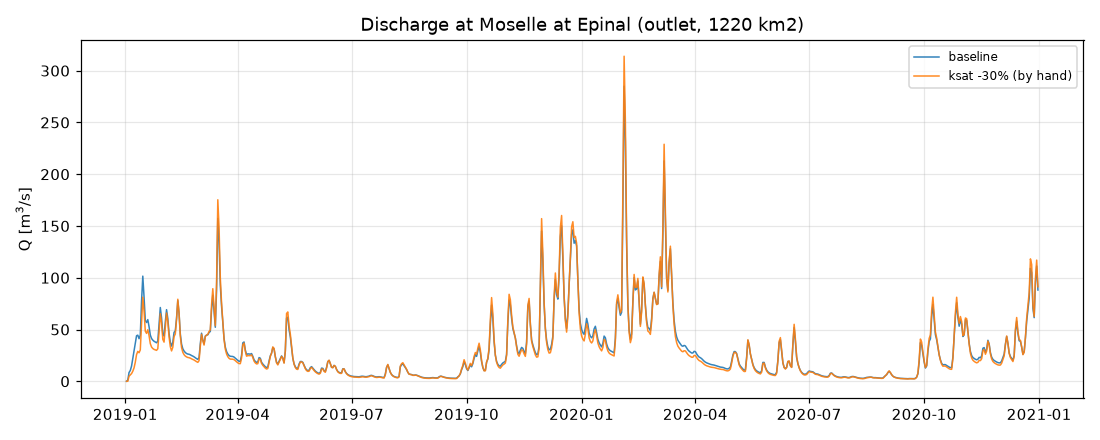

In [6]:
display(Image(str(W.plot_runs(["baseline", run.run_id]))))

## How your question reaches each agent
Every step below has a `QUESTION = "..."` line: edit it to ask your own. All architectures start the same way:
`session.start(QUESTION)` (or `run_interactive(session, QUESTION)`, which does the same) puts your question
into the graph's starting state twice:

- `query`: the plain question text, for steps that write their own prompt around it;
- `messages`: a chat history that starts with your question, for agents that converse.

What differs is **who sees it**:

| | Who reads your question |
|---|---|
| **A0** | `interpret` (as part of its prompt) and `report` (with the Wflow results) |
| **A1** | the ReAct agent, as the first chat message |
| **A2** | the generator, every round. The critic sees only the scores, not your question |
| **A3** | `classify`. Your clarifications are appended to it. The modeller subagent gets a task written by the plan, **not** your question |
| **A4** | Claude, as the task (on top of a system prompt with the model paths) |
| **A5** | the router, then the chosen branch (prompt, chat message or harness task) |
| **your graph** | agent nodes get the chat history. Plain-LLM and critic nodes get a transcript. A harness node gets `{query}` |

When an agent pauses to ask *you* something, buttons appear in the cell (`run_with_buttons`). Your click calls
`session.resume(answer)`, which sends the answer back into the paused step. The run continues from there; it
does not start over.

## Step 2: A0, plain LLM + fixed workflow

![A0 architecture](docs/figures/a0.png)

The LLM only translates the question into multipliers and writes the report. Code fixes the order of steps.

[llm] LLM [interpret]: {"label":"ksat -30%","multipliers":[{"parameter":"ksat_vertical","multiplier":0.7}],"rationale":"'30% less permeable' maps directly to a 30% reduction of vertical saturated hydraulic conductivity (KsatVer x0.7), which reduces infiltration and recharg
[node] node: interpret: {"label":"ksat -30%","multipliers":[{"parameter":"ksat_vertical","multiplier":0.7}],"rationale":"'30% less permeable' maps directly to a 30% reduction of vertical saturated hydraulic conductivity (KsatVer x0.7), which reduces infiltration and recharg
[model] wflow: Warning: 'wflow_version' is not recognized as a valid field of the [input] section in the TOML, this will be ignored.
[model] wflow: Info: Wflow version v1.0.4
[model] wflow: Info: Initialize model variables for model type sbm.
[model] wflow: Info: Cyclic parameters are provided by C:\Users\king_je\OneDrive - Stichting Deltares\Projects\LLM_general\DSD_agentic_course\LLMs-Agentic-Workflows-in-Hydrology-Training\wflow_moselle_epinal\

**Run:** `1110-134126-ksat-30-45e5` (KsatVer ×0.7) compared with the baseline run. The baseline run_id was not included in the result, so the baseline values below are back-calculated from the % changes.

**Epinal (GRDC 9116044), 2019–2020 excluding spin-up, m³/s**

| Statistic | Baseline (derived) | ksat −30% | Change |
|---|---|---|---|
| Peak (max, 2020-02-04) | ~284.9 | 313.96 | **+10.2%** (~+29 m³/s) |
| Q95 (high flows) | ~96.8 | 99.33 | +2.6% |
| Mean | ~29.4 | 29.12 | −0.8% |
| Q10 (low flows) | ~3.82 | 3.48 | **−9.0%** (~−0.34 m³/s) |

**Explanation:** Lower vertical permeability sends more rainfall into fast runoff instead of infiltration, so floods get higher and baseflow drops. The water balance barely changes; the flow regime just becomes flashier.

**Caveats:**
- This is a single 2-year simulation, so the peak change rests on essentially one event (Feb 2020).
- The model is uncalibrated against GRDC observations here, so treat these as relative sensitivities, not absolute forecasts.

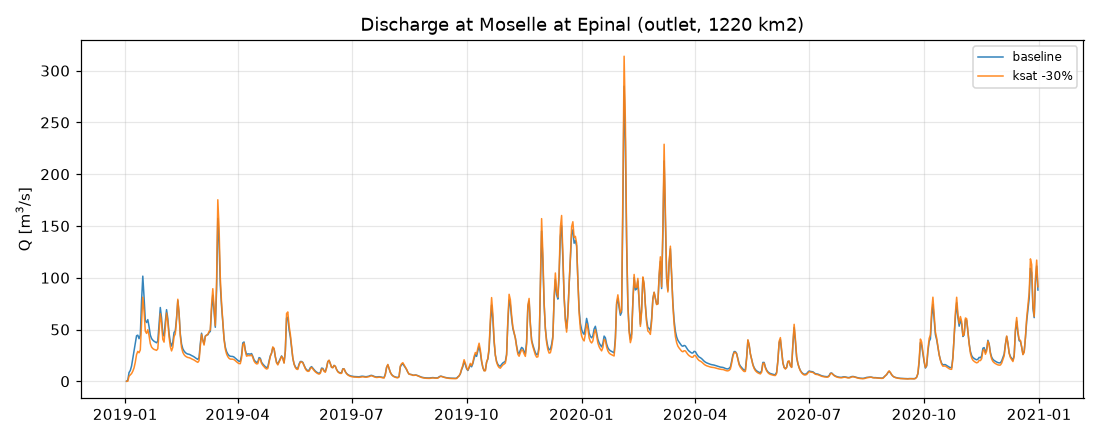

LLM calls 2 | tool calls 0 | Wflow runs 1 | tokens 2,840 (in 2,141, out 699, cached 0)
time 43.6 s = LLM 9.6 + Wflow 20.1 + other 13.9 | cost $0.0225 | runs: ['1110-134126-ksat-30-45e5']
scoreboard entry: 5f45aaa8  ->  rate it: scoreboard.rate('5f45aaa8', 1..5)


In [7]:
QUESTION = "What happens to peak and low flows at Epinal if soils become 30% less permeable?"   # edit me
out = run_interactive(R.create_session("a0", provider=PROVIDER, on_event=show), QUESTION)
report(out)

## Step 3: A1, single agent (ReAct)

![A1 architecture](docs/figures/a1.png)

One LLM with tools in a loop. **Customise it:** change the system prompt or remove a tool set, and see how the
behaviour changes. Try a question that needs *two* scenarios, for example comparing +20% and -20% soil thickness.

In [8]:
from hydroagent.architectures import a1_react
from hydroagent.architectures.common import make_session

MY_PROMPT = a1_react.SYSTEM_PROMPT          # edit me
MY_TOOLSETS = ("parameters", "simulation", "analysis")   # try removing "analysis"

session = make_session("a1", a1_react.build, provider=PROVIDER, on_event=show,
                       system_prompt=MY_PROMPT, toolsets=MY_TOOLSETS)
QUESTION = "Compare +20% and -20% soil thickness: which affects low flows at Epinal more?"   # edit me
out = run_interactive(session, QUESTION)
report(out)

[llm] LLM [model]: -> wants to call: list_parameters({})
[node] node: model: 
[tool_call] tool: list_parameters: {}
[node] node: tools: 
[llm] LLM [model]: -> wants to call: run_scenario({"multipliers": {"soil_thickness": 1.2}, "label": "soil thickness +20%"}), run_scenario({"multipliers": {"soil_thickness": 0.8}, "label": "soil thickness -20%"})
[node] node: model: 
[tool_call] tool: run_scenario: {'multipliers': {'soil_thickness': 1.2}, 'label': 'soil thickness +20%'}
[tool_call] tool: run_scenario: {'multipliers': {'soil_thickness': 0.8}, 'label': 'soil thickness -20%'}
[model] wflow: Warning: 'wflow_version' is not recognized as a valid field of the [input] section in the TOML, this will be ignored.
[model] wflow: Info: Wflow version v1.0.4
[model] wflow: Info: Initialize model variables for model type sbm.
[model] wflow: Info: Cyclic parameters are provided by C:\Users\king_je\OneDrive - Stichting Deltares\Projects\LLM_general\DSD_agentic_course\LLMs-Agentic-Workflows-in-Hydrology

**Answer: −20% soil thickness changes low flows at Epinal more.** It lowers Q10 by 24%, while +20% raises it by 18.6%.

Results at Epinal (GRDC 9116044), as % change from the automatic baseline run:

| Run | Mean | Peak | Q95 (high flow) | Q10 (low flow) |
|---|---|---|---|---|
| Soil thickness +20% (`1110-134224-soil-thickness-20-4d19`) | 29.29 m³/s (−0.2%) | 282.2 (−1.0%) | 93.1 (−3.8%) | **4.54 (+18.6%)** |
| Soil thickness −20% (`1110-134224-soil-thickness-20-aa55`) | 29.45 m³/s (+0.3%) | 289.0 (+1.4%) | 100.1 (+3.3%) | **2.91 (−24.0%)** |

The baseline Q10 works out to about 3.8 m³/s. That figure is back-calculated from the percentages, not read from the baseline run directly.

- **Low flows:** the effect isn't symmetric. Thinner soil cuts Q10 by about 0.9 m³/s, while thicker soil adds about 0.7 m³/s. Shallow soils make low flows more vulnerable.
- **Mean flow:** almost unchanged (±0.3%). Soil thickness mainly changes when water reaches the river, not how much does over the year.
- **High flows:** the change is small (±3–4% in Q95, ±1% in peak). Thicker soil damps floods slightly and thinner soil makes them slightly sharper.

**Why:** soil thickness sets how much water the soil can store and release slowly to the river in dry spells. Removing 20% of that storage shortens the release more than adding 20% lengthens it. During droughts the soil is limited by how much it can hold, so lost capacity hurts more than extra capacity helps.

LLM calls 3 | tool calls 3 | Wflow runs 2 | tokens 9,277 (in 8,307, out 970, cached 0)
time 48.3 s = LLM 10.6 + Wflow 55.6 + other 0.0 | cost $0.0526 | runs: ['1110-134224-soil-thickness-20-aa55', '1110-134224-soil-thickness-20-4d19']
scoreboard entry: f23f9ce9  ->  rate it: scoreboard.rate('f23f9ce9', 1..5)


## Step 4: A2, generator-critic loop (calibration)

![A2 architecture](docs/figures/a2.png)

There are no observed discharge series in this repo, so we use a **twin experiment**. A hidden "truth" run
made with secret multipliers plays the role of observations, and the loop tries to recover it.
**Knobs:** `max_iter`, `target_kge`, `critic="llm"` vs `"rule"`. Is the LLM critic worth its tokens?

[llm] LLM [generator]: {"reasoning":"No runs yet (no run_ids to base conclusions on); start from the default HydroMT parameterisation (all multipliers 1.0) to establish a baseline KGE, r, alpha and beta for GRDC 9116044 before adjusting.","multipliers":[{"parameter":"ksat_
[node] node: generator: {'ksat_vertical': 1.0, 'soil_thickness': 1.0, 'ksat_horizontal_ratio': 1.0} | No runs yet (no run_ids to base conclusions on); start from the default HydroMT parameterisation (all multipliers 1.0) to establish a baseline KGE, r, alpha and beta for GR
[model] wflow: Warning: 'wflow_version' is not recognized as a valid field of the [input] section in the TOML, this will be ignored.
[model] wflow: Info: Wflow version v1.0.4
[model] wflow: Info: Initialize model variables for model type sbm.
[model] wflow: Info: Cyclic parameters are provided by C:\Users\king_je\OneDrive - Stichting Deltares\Projects\LLM_general\DSD_agentic_course\LLMs-Agentic-Workflows-in-Hydrology-Training\wflow_moselle_epinal\

**Calibration summary: Moselle at Epinal (GRDC 9116044), 2019-2020 excluding 3-month spin-up.** No run_ids were provided, so this is based on iter 1 and iter 2 of the history.

1. **Best set (iter 2):** ksat_vertical ×1.2, soil_thickness ×1.3, ksat_horizontal_ratio ×1.5 gives KGE 0.975, NSE 0.983, PBIAS +2.2%.
2. **KGE progression:** 0.860 (iter 1, default) → 0.975 (iter 2), +0.115. NSE rose 0.958 → 0.983.
3. **Driver of the gain:** variability (α) fell from 1.137 to 1.007, as the default overestimated flow variability by about 14%. Correlation was already high and barely changed (0.990 → 0.992). Bias (β) improved slightly (1.030 → 1.022).
4. **Remaining error:** the leftover KGE error is now dominated by the +2.2% volume overestimate, not timing or variability. Further gains need water-balance parameters, e.g. evaporation or interception, rather than soil hydraulics.
5. **Equifinality caveat:** all three multipliers changed at once in a single step, so the gain cannot be attributed to any one parameter. Other combinations (e.g. thicker soil alone) may score equally well. Two iterations is not a search, so the optimum and parameter identifiability are untested.
6. **Validation caveat:** calibration and evaluation use the same ~21-month window, with no independent validation period. It also covers only two hydrological years, so how the parameters perform under other conditions (e.g. extreme floods or droughts) is unknown.
7. **Plausibility check:** NSE 0.96 for an uncalibrated 1 km model is unusually high. Please confirm the observations are real GRDC data and not a synthetic/reference model run.
8. **Next steps:** run one-at-a-time sensitivity tests around iter 2, then do a split-sample validation (e.g. extend to 2017-2018) before adopting these parameters.

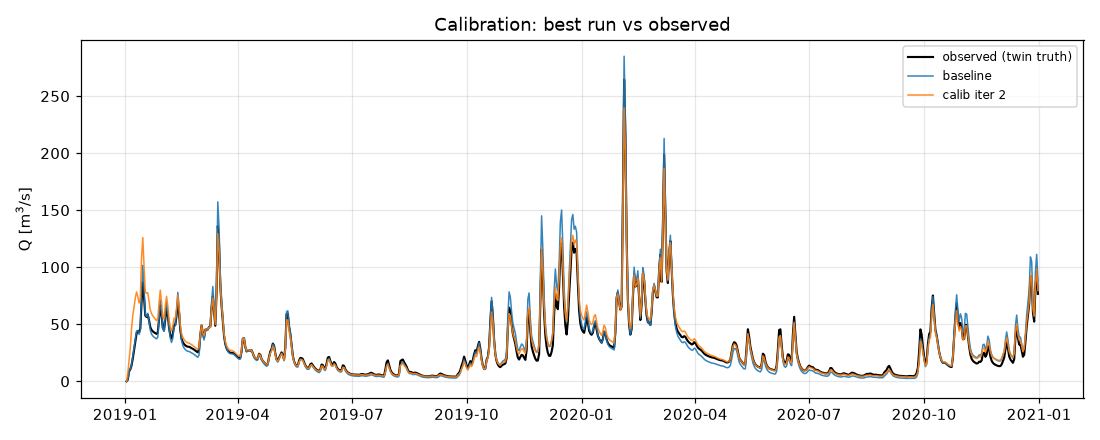

LLM calls 4 | tool calls 0 | Wflow runs 2 | tokens 6,480 (in 4,045, out 2,435, cached 0)
time 60.7 s = LLM 27.9 + Wflow 32.5 + other 0.2 | cost $0.0649 | runs: ['1110-134333-calib-iter-1-e3bc', '1110-134402-calib-iter-2-dabb']
scoreboard entry: d2d0209e  ->  rate it: scoreboard.rate('d2d0209e', 1..5)


In [9]:
twin.ensure_truth()
QUESTION = ("Calibrate ksat_vertical, soil_thickness and ksat_horizontal_ratio so the Epinal discharge matches "
            "observations (target KGE 0.95).")   # edit me
out = run_interactive(R.create_session("a2", provider=PROVIDER, on_event=show, max_iter=4, critic="llm"), QUESTION)
report(out)

In [10]:
print("the truth was:", twin.reveal_truth())   # debrief: equifinality?

the truth was: {'ksat_vertical': 0.4, 'soil_thickness': 1.6, 'ksat_horizontal_ratio': 3.0}


## Step 5: A3, Director with subagents and human-in-the-loop

![A3 architecture](docs/figures/a3.png)

This follows the Director pattern from the Agent4Hydro project:
- an allow-list of scenario types;
- clarification questions when inputs are missing;
- plan approval before any compute is spent;
- Modeller and Analyst subagents, with retries and escalation.

The agent pauses to ask you questions. Answer with the **buttons** that appear in the cell output:
a text box + **Send** for open questions (try `-30`), **Approve / Reject** for the plan. After each click the
trace and result appear under the buttons. Try an out-of-scope request too.

In [11]:
QUESTION = "What if the soils in the Moselle become less permeable?"   # edit me (no % on purpose: it will ask)
a3 = R.create_session("a3", provider=PROVIDER, on_event=show)
a3_run = run_with_buttons(a3, QUESTION, report)   # a3_run["out"] holds the latest outcome

[llm] LLM [classify]: {"scenario":"soil_permeability","change_pct":null,"gauge":"9116044","reason":"The user asks about reduced soil permeability in the Moselle basin without specifying a magnitude, which maps to the soil_permeability scenario at the default Epinal gauge.
[node] node: classify: {"scenario":"soil_permeability","change_pct":null,"gauge":"9116044","reason":"The user asks about reduced soil permeability in the Moselle basin without specifying a magnitude, which maps to the soil_permeability scenario at the default Epinal gauge.
[human] waiting for human: Scenario 'soil_permeability' recognised. By how many percent should 'ksat_vertical' change? (e.g. -30 for 30% lower)


### 🙋 The agent asks you

Scenario 'soil_permeability' recognised. By how many percent should 'ksat_vertical' change? (e.g. -30 for 30% lower)

Answer with the buttons below.

## Step 6: A4, Claude Agent SDK harness + skills (code agent)

![A4 architecture](docs/figures/a4.png)

The harness writes and runs its own Python on `staticmaps.nc` / `output.nc`. It works in a sandboxed
workspace and runs Wflow through an MCP tool.

It loads **skills** on demand:
- `wflow-toml`
- `netcdf-analysis`
- `hydrology-env` (the repo's environment skill)

Watch for `tool: Skill` in the trace.

In [12]:
from hydroagent.harness.claude_runner import available_skills, run_harness

[(s["name"], s["description"][:80]) for s in available_skills()]

[('flow-duration-curve',
  'Compute and plot flow-duration curves and exceedance flows (Q10, Q50, Q90, Q95) '),
 ('jude-styles', 'my personal styling choices for figures'),
 ('netcdf-analysis',
  'Read, analyse and modify Wflow NetCDF files (staticmaps.nc parameters, output.nc'),
 ('wflow-toml',
  'How Wflow.jl 1.x TOML files are structured and how to change parameters safely ('),
 ('hydrology-env',
  'Installs and verifies the hydrology training stack (Git, uv >= 0.13.6, Julia, Py')]

[harness] session start: model=claude-opus-5-5 skills=['flow-duration-curve', 'hydrology-env', 'jude-styles', 'netcdf-analysis', 'wflow-toml', 'deep-research', 'dataviz', 'update-config', 'verify', 'debug', 'code-review', 'simplify', 'batch', 'fewer-permission-prompts', 'doc
[tool_call] tool: Skill: {"skill": "netcdf-analysis"}
[tool_call] tool: ToolSearch: {"query": "select:mcp__hydro__run_wflow_scenario,mcp__hydro__get_run_summary", "max_results": 2}
[tool_call] tool: Skill: {"skill": "jude-styles"}
[tool_call] tool: Write: {"file_path": "C:/Users/king_je/OneDrive - Stichting Deltares/Projects/LLM_general/DSD_agentic_course/LLMs-Agentic-Workflows-in-Hydrology-Training/exercises/02_agentic_workflows/output/harness/1110-134706-4944/edit_static.py", "content": "import xarr
[llm] Claude: Jude Styles wasn't requested, so I'll use standard styling.
[tool_call] tool: Bash: {"command": "cd \"C:/Users/king_je/OneDrive - Stichting Deltares/Projects/LLM_general/DSD_agentic_course/LLMs-Agentic-W

I halved the soil permeability in the Fresse-sur-Moselle sub-catchment and ran the model. The annual-maximum discharge went up by 21–32 % at Fresse-sur-Moselle but only by about 2 % at Epinal.

**What I changed:** `soil_ksat_vertical` × 0.5 in the 124 grid cells where `subcatchment_grdc == 9116039`. The mean value there dropped from 1559 to 780 mm/day, and every other cell is unchanged. The edited copy is `staticmaps_fresse_ksat05.nc` in the workspace.

**Runs compared:** `baseline` vs `1110-134740-fresse-ksat-half-7459`. Both are compared from 2019-04-01, after the spin-up period.

**Annual-maximum discharge**

| Gauge | Year | Baseline | Scenario | Change |
|---|---|---|---|---|
| Fresse-sur-Moselle (9116039) | 2019* | 7.8 m³/s | 9.5 m³/s | +1.6 m³/s (+20.7 %) |
| Fresse-sur-Moselle (9116039) | 2020 | 12.0 m³/s | 15.9 m³/s | +3.9 m³/s (+32.4 %) |
| Epinal (9116044) | 2019* | 150.1 m³/s | 153.0 m³/s | +2.8 m³/s (+1.9 %) |
| Epinal (9116044) | 2020 | 284.9 m³/s | 291.2 m³/s | +6.2 m³/s (+2.2 %) |

*2019 covers April to December only.

- **Timing:** the peaks fall on the same dates (16 Dec 2019 and 4 Feb 2020 at Epinal). At Fresse the 2019 peak moved one day earlier, from 25 to 24 Dec.
- **Why the peaks rise:** with less water soaking into the soil, more rain runs off quickly during storms. Between storms Fresse's flow is slightly lower, because less water is stored in the soil to feed the river later.
- **Why Epinal barely changes:** the Fresse sub-catchment is a small part of the 1220 km² basin above Epinal. Mean flow at Epinal changed by −0.1 % and the 95th-percentile high flow by +0.7 %.

**Figure:** `C:/Users/king_je/OneDrive - Stichting Deltares/Projects/LLM_general/DSD_agentic_course/LLMs-Agentic-Workflows-in-Hydrology-Training/exercises/02_agentic_workflows/output/harness/1110-134706-4944/annual_max_fresse_ksat_half.png` shows the daily flow at both gauges and bars of the annual maxima with the percentage change.

**Scripts:** `edit_static.py` and `compare.py` in the workspace.

skills loaded: ['netcdf-analysis', 'jude-styles'] | usage: {'model': 'anthropic:claude-opus-5-5', 'llm_calls': 7, 'tool_calls': 9, 'wflow_runs': 1, 'input_tokens': 17, 'output_tokens': 4056, 'cache_read_tokens': 172185, 'cache_write_tokens': 34977, 'total_tokens': 211235, 'wall_time_s': 83.0, 'llm_s': 36.2, 'model_s': 19.3, 'other_s': 27.5, 'julia_startup_s': 0.0, 'cost_usd': 0.2905, 'cost_source': 'pricing.yml', 'by_node': {'claude_harness': {'llm_calls': 7, 'input_tokens': 17, 'output_tokens': 4056, 'cache_read_tokens': 172185, 'llm_s': 36.23}}} | workspace: C:\Users\king_je\OneDrive - Stichting Deltares\Projects\LLM_general\DSD_agentic_course\LLMs-Agentic-Workflows-in-Hydrology-Training\exercises\02_agentic_workflows\output\harness\1110-134706-4944


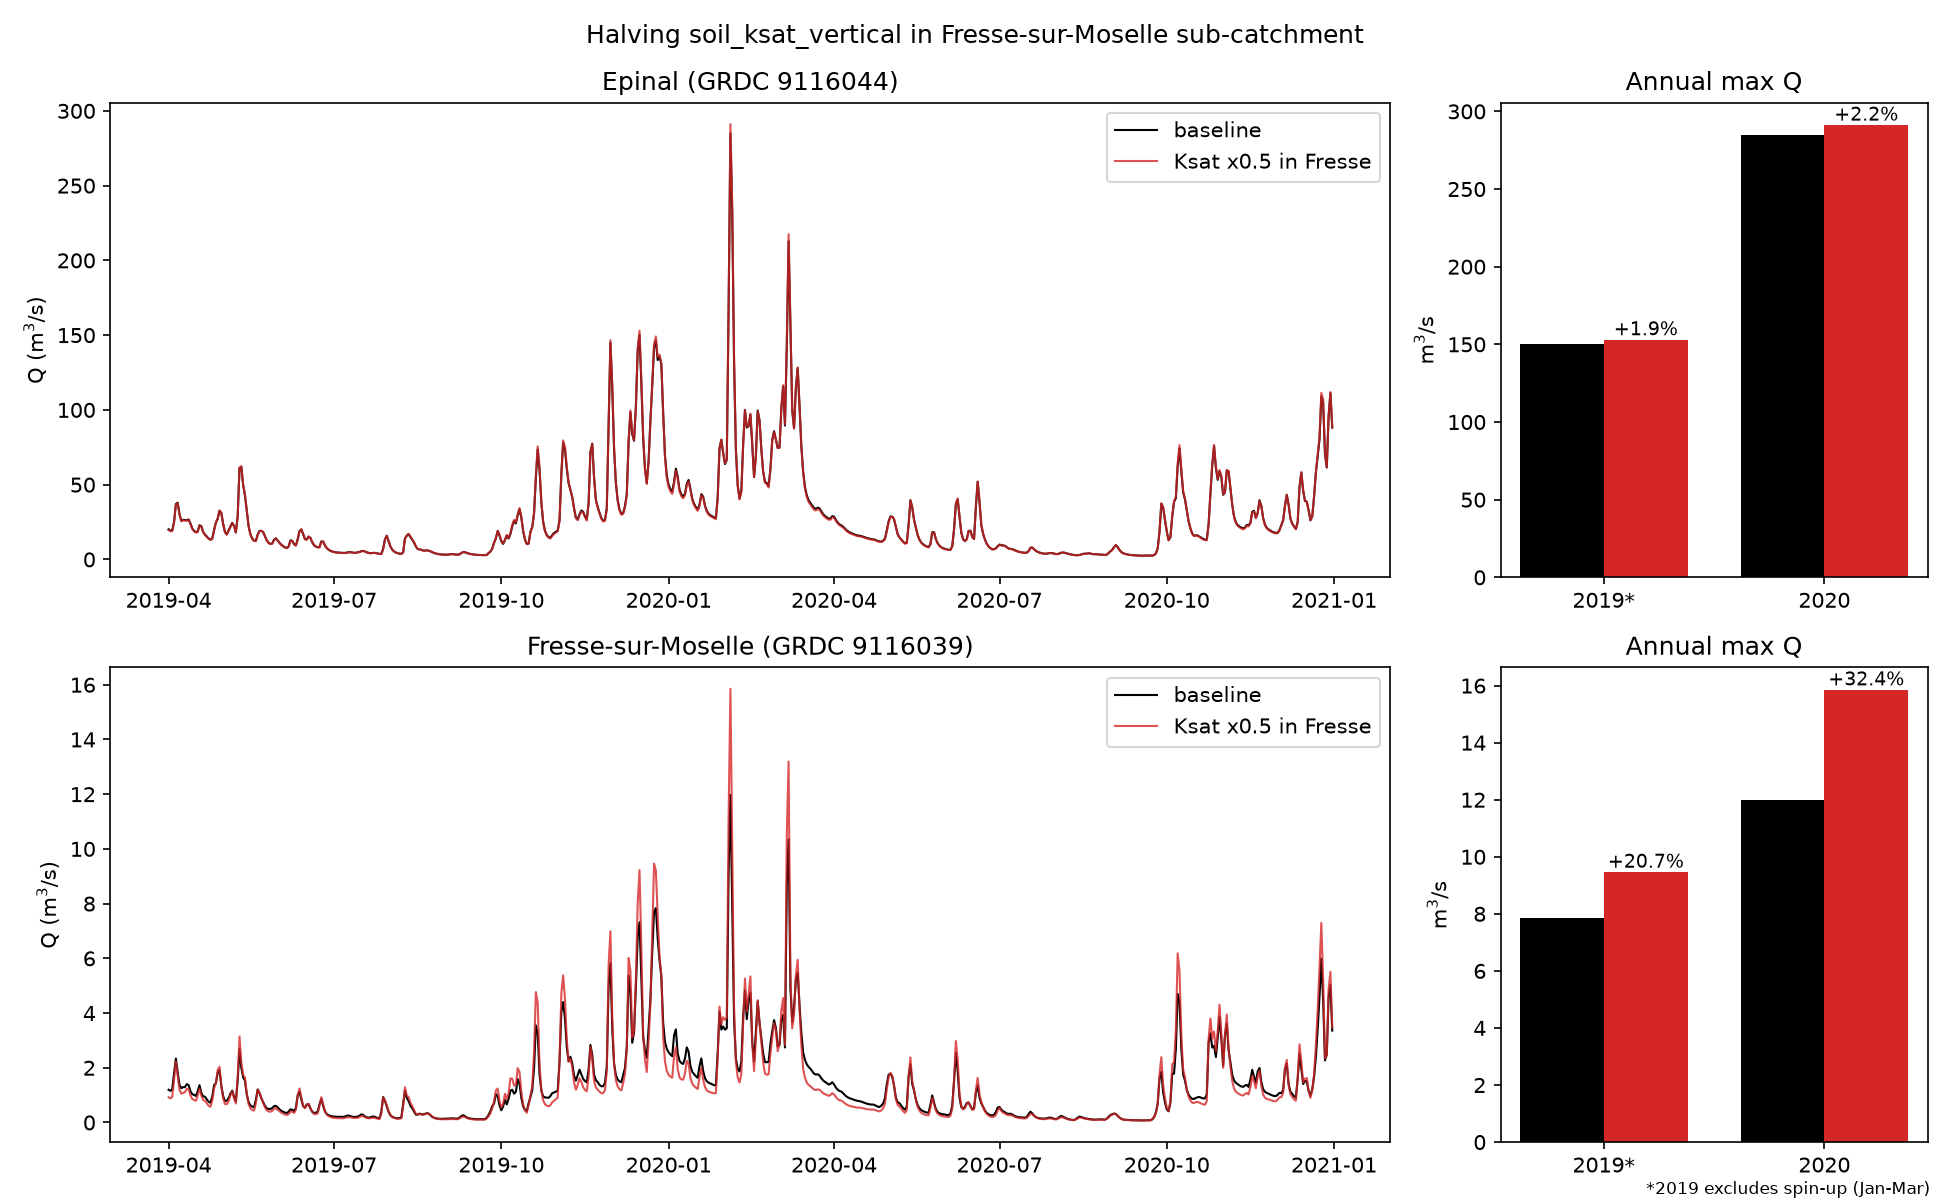

In [13]:
HARNESS_QUESTION = ("Halve the soil permeability (soil_ksat_vertical) only in the Fresse-sur-Moselle sub-catchment "
                    "(GRDC 9116039), run the model, and compare the annual-maximum discharge at Epinal and at "
                    "Fresse-sur-Moselle with the baseline. Make one figure.")   # edit me (also used by A4m below)
out_a4 = R.create_session("a4", on_event=show).start(HARNESS_QUESTION)
report(out_a4)
print("skills loaded:", out_a4.state.get("skills_loaded"), "| workspace:", out_a4.state.get("workspace"))

### A4m: the same task with Mistral Vibe

![A4m architecture](docs/figures/a4m.png)

Mistral's own coding agent, **Mistral Vibe**, with your Mistral deployment on Azure Foundry. It gets the same
workspace layout, the same skills and the same Wflow tools as A4, so this is a like-for-like comparison of two
harnesses and two models. Install Vibe once: `uv tool install mistral-vibe`.

Compare the two outputs (and the scoreboard below): did both load a skill? Same numbers? Tokens, time, cost?
Rate both answers with `scoreboard.rate(...)`.

In [ ]:
out_a4m = R.create_session("a4m", on_event=show).start(HARNESS_QUESTION)
report(out_a4m)
print("skills loaded:", out_a4m.state.get("skills_loaded"), "| workspace:", out_a4m.state.get("workspace"))

### Write your own skill
Edit the cell below, then run the harness on a task that needs it. Did the agent load it (`skills loaded`)?
Does it help compared with a run *without* the skill (`skills=[...]` excluding it)?
Template: `skills/_template/SKILL.md`.

In [14]:
SKILL_NAME = "flow-duration-curve"
SKILL_MD = """---
name: flow-duration-curve
description: Compute and plot flow-duration curves and exceedance flows (Q10, Q50, Q90, Q95) from Wflow output.csv at a gauge. Use for low-flow / drought or flow-regime questions.
---

# Flow-duration curve

1. Read `<run>/output/output.csv`, column `river_q_<gauge>`; drop dates before 2019-04-01 (spin-up).
2. Sort discharge descending; exceedance probability p = rank / (n + 1).
3. Qx = discharge exceeded x% of the time (Q90 = low flow, Q10 = high flow).
4. Plot with log y-axis, x = exceedance [%]; one line per run; save PNG in the workspace.
5. Report a table of Q10, Q50, Q90, Q95 per run and the % change vs baseline.
"""
d = EXERCISE_DIR / "skills" / SKILL_NAME
d.mkdir(parents=True, exist_ok=True)
(d / "SKILL.md").write_text(SKILL_MD, encoding="utf-8")

r = run_harness("Make flow-duration curves at Epinal for the baseline and the 'ksat -30% (by hand)' run, and report "
                "Q10, Q50, Q90 for both.", on_event=show)
display(Markdown(r.answer or r.error))
print("skills loaded:", r.skills_loaded, "| usage:", r.usage)

[harness] session start: model=claude-opus-5-5 skills=['flow-duration-curve', 'hydrology-env', 'jude-styles', 'netcdf-analysis', 'wflow-toml', 'deep-research', 'dataviz', 'update-config', 'verify', 'debug', 'code-review', 'simplify', 'batch', 'fewer-permission-prompts', 'doc
[tool_call] tool: Skill: {"skill": "flow-duration-curve"}
[tool_call] tool: Skill: {"skill": "jude-styles"}
[tool_call] tool: Bash: {"command": "cd \"C:/Users/king_je/OneDrive - Stichting Deltares/Projects/LLM_general/DSD_agentic_course/LLMs-Agentic-Workflows-in-Hydrology-Training/exercises/02_agentic_workflows/output/runs\"; ls; for d in */; do echo \"== $d\"; ls \"$d\"; cat \"$
[tool_call] tool: Bash: {"command": "cd \"C:/Users/king_je/OneDrive - Stichting Deltares/Projects/LLM_general/DSD_agentic_course/LLMs-Agentic-Workflows-in-Hydrology-Training/exercises/02_agentic_workflows/output/runs\"; ls -d *by-hand*; for d in *by-hand*; do ls $d; ls $d/o
[tool_call] tool: Bash: {"command": "cd \"C:/Users/king_je/OneDriv

I made flow-duration curves for both runs at Epinal (gauge `river_q_9116044`, GRDC 9116044). I left out the spin-up, so they cover 2019-04-01 to 2020-12-31 (641 days).

| Run | run_id | Q10 [m³/s] | Q50 [m³/s] | Q90 [m³/s] |
|---|---|---|---|---|
| Baseline | `baseline` | 73.70 | 18.44 | 3.82 |
| ksat −30% (by hand) | `1110-133857-ksat-30-by-hand-9965` | 74.21 (+0.7%) | 17.39 (−5.7%) | 3.45 (−9.7%) |

Q95 went from 3.19 to 2.88 m³/s (−9.5%).

Cutting vertical ksat by 30% (`ksat_vertical` × 0.7) leaves high flows almost unchanged, with Q10 up slightly. Median flow drops by about 6% and low flows by about 10%. Less water soaks into the soil, so there is less baseflow to keep the river going in dry periods.

There are 8 runs named "ksat −30% (by hand)", made between 2026-11-09 and 2026-11-10. They all have the same settings and give exactly the same `output.csv`, so I used the latest one; any of the others would give the same numbers.

Files are in `exercises/02_agentic_workflows/output/harness/1110-134840-02c4/`:
- **Figure:** `fdc_epinal_baseline_vs_ksat30.png` (log y-axis)
- **Table:** `fdc_epinal_table.csv`
- **Script:** `fdc.py`

skills loaded: ['flow-duration-curve', 'jude-styles'] | usage: {'model': 'anthropic:claude-opus-5-5', 'llm_calls': 7, 'tool_calls': 8, 'wflow_runs': 0, 'input_tokens': 14, 'output_tokens': 2910, 'cache_read_tokens': 200143, 'cache_write_tokens': 15363, 'total_tokens': 218430, 'wall_time_s': 57.7, 'llm_s': 27.6, 'model_s': 0.0, 'other_s': 30.1, 'julia_startup_s': 0.0, 'cost_usd': 0.1751, 'cost_source': 'pricing.yml', 'by_node': {'claude_harness': {'llm_calls': 7, 'input_tokens': 14, 'output_tokens': 2910, 'cache_read_tokens': 200143, 'llm_s': 27.64}}}


## Step 7: A5, composed router

![A5 architecture](docs/figures/a5.png)

Try a knowledge question, a uniform parameter scenario, and an open-ended code task. Which route does each take?
What does each cost?

In [15]:
QUESTIONS = [   # edit me: each question gets its own session; watch which route the router picks
    "What does the KsatHorFrac parameter do in wflow_sbm?",                  # expect: simple_answer
    "Increase river roughness by 50%: how does the Epinal peak change?",     # expect: parameter_scenario
    # "Halve soil_ksat_vertical only in sub-catchment 9116039 and compare annual maxima",  # open_ended_code (slow)
]
for q in QUESTIONS:
    run_with_buttons(R.create_session("a5", provider=PROVIDER, on_event=show), q, report)  # buttons if unsure

[llm] LLM [route]: {"route":"simple_answer","confidence":0.95,"reason":"This is a knowledge question about what the KsatHorFrac parameter means in wflow_sbm. It is the multiplication factor that converts vertical saturated hydraulic conductivity into horizontal (latera
[node] node: route: {"route":"simple_answer","confidence":0.95,"reason":"This is a knowledge question about what the KsatHorFrac parameter means in wflow_sbm. It is the multiplication factor that converts vertical saturated hydraulic conductivity into horizontal (latera
[llm] LLM [simple_answer]: # KsatHorFrac in wflow_sbm

**What it is.** KsatHorFrac is a dimensionless multiplier that converts vertical saturated hydraulic conductivity into horizontal (lateral) conductivity. It controls lateral subsurface flow:

- kh₀ = KsatHorFrac × KsatVer₀
[node] node: simple_answer: 
[node] node: human_check: confidence above threshold - no human check


# KsatHorFrac in wflow_sbm

**What it is.** KsatHorFrac is a dimensionless multiplier that converts vertical saturated hydraulic conductivity into horizontal (lateral) conductivity. It controls lateral subsurface flow:

- kh₀ = KsatHorFrac × KsatVer₀ (at the soil surface)
- kh(z) = kh₀ · e^(−f·z), which decays with depth using the same f as KsatVer in the default exponential profile.
- Lateral subsurface flow is routed with a kinematic wave between cells. The flux is roughly kh × saturated thickness × local slope × flow width.

**Why it exists.** It lumps several effects that make effective lateral conductivity much larger than point or vertical Ksat:

- soil anisotropy
- macropores and preferential flow paths
- scale effects (1 km cells versus pedotransfer-function Ksat)

Typical values are about 1–1000. HydroMT's default is a uniform 100. Newer HydroMT-wflow versions can also supply a regionalized map (Bouaziz et al., 2022).

**Hydrological effect if you increase it:**

- faster lateral drainage of the saturated store toward the river
- deeper water tables and less saturation-excess overland flow
- lower, broader peaks
- higher, more sustained baseflow, with drainage shifted from storm events toward recessions

Decreasing it does the opposite: wetter hillslopes, more saturation-excess runoff, flashier peaks, and faster low-flow decline.

**In practice.** It is one of the most sensitive calibration parameters for wflow_sbm. It interacts strongly with ksat_vertical and f. A ksat_vertical × 0.7 scenario also lowers horizontal conductivity by 30% unless KsatHorFrac is compensated. In the TOML it is `lateral.subsurface.ksathorfrac` (Wflow.jl v0.x). In v1.x it is the standard name `subsurface_water__horizontal-to-vertical_saturated_hydraulic_conductivity_ratio`.

*Basis: model documentation and general knowledge only. No run_ids were used; I have not quantified sensitivity for the Moselle/Epinal model.*

LLM calls 2 | tool calls 0 | Wflow runs 0 | tokens 2,300 (in 954, out 1,346, cached 0)
time 15.1 s = LLM 15.0 + Wflow 0.0 + other 0.0 | cost $0.0307 | runs: []
scoreboard entry: 8e533e81  ->  rate it: scoreboard.rate('8e533e81', 1..5)
[llm] LLM [route]: {"route":"parameter_scenario","confidence":0.9,"reason":"The request is a uniform parameter multiplier: river Manning's n (river roughness) times 1.5. The question is then answered with a standard statistic, the peak discharge at the Epinal gauge, co
[node] node: route: {"route":"parameter_scenario","confidence":0.9,"reason":"The request is a uniform parameter multiplier: river Manning's n (river roughness) times 1.5. The question is then answered with a standard statistic, the peak discharge at the Epinal gauge, co
[llm] LLM [model]: -> wants to call: list_parameters({})
[tool_call] tool: list_parameters: {}
[llm] LLM [model]: -> wants to call: run_scenario({"multipliers": {"river_manning_n": 1.5}, "label": "river n +50%"})
[tool_call]

Making the river 50% rougher lowers the Epinal peak only a little, by about **2%**.

I ran this by multiplying `river_manning_n` by 1.5 (run **1110-134957-river-n-50-69c8**) and compared it with the automatic baseline run.

| Statistic at Epinal (GRDC 9116044) | River roughness +50% | Change vs baseline |
|---|---|---|
| Peak flow (2020-02-04) | 279.2 m³/s | **−2.0%** (about −5.7 m³/s; baseline ≈ 284.9 m³/s, worked out from the % change) |
| Q95 (high flows) | 97.0 m³/s | +0.1% |
| Mean flow | 29.35 m³/s | 0.0% |
| Q10 (low flows) | 3.82 m³/s | −0.1% |

**Why:** a rougher channel slows the flood wave and spreads it out a little, but it doesn't change how much water there is. The mean and low flows stay the same, and only the highest daily peak drops. The effect is small because the rivers above Epinal are short (1220 km²), so water spends little time in them. The peak depends much more on how fast water runs off the hillsides. Also, the model saves daily values, which hides much of the flattening that happens within a single day.

If the goal is lower flood peaks, changing the soil and runoff parameters (`ksat_vertical`, `soil_thickness`, `land_manning_n`) would likely have a much bigger effect than changing channel roughness.

LLM calls 4 | tool calls 2 | Wflow runs 1 | tokens 9,354 (in 8,562, out 792, cached 0)
time 26.8 s = LLM 10.2 + Wflow 16.6 + other 0.1 | cost $0.0501 | runs: ['1110-134957-river-n-50-69c8']
scoreboard entry: 8f43d0ef  ->  rate it: scoreboard.rate('8f43d0ef', 1..5)


## Step 8: Build your own graph (JSON)
This is the same spec the Streamlit canvas produces.

Node types:
- `llm_agent`
- `plain_llm`
- `tool_step`
- `critic` (edges labelled `approved` / `revise`)
- `router` (edges labelled with a description of when to take them)
- `human`
- `claude_harness`

In [ ]:
from hydroagent.builder.compile import make_custom_session, validate

my_graph = {
    "name": "my_agent",
    "nodes": [
        {"id": "start", "type": "start"},
        {"id": "modeller", "type": "llm_agent", "config": {"toolsets": ["parameters", "simulation"],
                                                         "system_prompt": "Run the scenario(s) needed. Be brief."}},
        {"id": "plot", "type": "tool_step", "config": {"action": "plot_all_runs"}},
        {"id": "critic", "type": "critic", "config": {"criteria": "Gives % change for peak AND low flow with run_ids.",
                                                    "max_loops": 1}},
        {"id": "writer", "type": "plain_llm", "config": {"instruction": "Write a 3-line note for a water manager."}},
        {"id": "end", "type": "end"},
    ],
    "edges": [
        {"source": "start", "target": "modeller"}, {"source": "modeller", "target": "plot"},
        {"source": "plot", "target": "critic"}, {"source": "critic", "target": "modeller", "label": "revise"},
        {"source": "critic", "target": "writer", "label": "approved"}, {"source": "writer", "target": "end"},
    ],
}
print(validate(my_graph) or "valid")
QUESTION = "How do low flows at Epinal respond to a 50% higher crop factor?"   # edit me
run_with_buttons(make_custom_session(my_graph, provider=PROVIDER, on_event=show), QUESTION, report)

## Debrief: which architecture strikes the right balance?
Every run above was logged to the **scoreboard** (`output/scoreboard.jsonl`) with its tokens, time split
(LLM vs Wflow vs other) and estimated cost (`pricing.yml`). Only *you* can judge the quality: rate each
answer from 1 to 5 with `scoreboard.rate(entry_id, score)`, using the entry ids printed by `report()`.
Then compare. A fair comparison uses the same question for every architecture, ideally repeated 2-3 times,
because agents are not deterministic.

In [ ]:
# scoreboard.rate("<entry id>", 4)          # rate your answers first
sb = scoreboard.load()
display(sb[["id", "arch", "status", "quality", "total_tokens", "wall_time_s", "llm_s", "model_s", "cost_usd",
            "question"]].tail(20))
summary = scoreboard.summary(sb)
summary["tokens_per_quality_pt"] = (summary["total_tokens"] / summary["quality"]).round(0)
summary

In [ ]:
# Where does the time go? LLM vs hydrological model, per architecture
summary.set_index("arch")[["llm_s", "model_s"]].plot.barh(stacked=True, figsize=(7, 3), xlabel="seconds");


Questions to discuss:
- Which questions did **A0** handle as well as the agents?
- Where did **A1** go wrong, if anywhere?
- What did **A3** guarantee that A1 cannot?
- When is the **harness (A4)** worth its cost and its unpredictability?
- Where would a **skill** be better than a new tool, or a new subagent?